# 04 — Avaliação dos detectores de drift (offline)

Este notebook responde: **os detectores e os limiares do laço de produção acertam o que foi injetado?** Ele usa a verdade
do simulador (o cronograma de drift), por isso só existe offline: em produção não há `drift_spec.json`
(`docs/decisions.md`, #16).

**Protocolo.** Quatro simulações novas, nunca a oficial (semente 42):

| Semente | Papel |
|---|---|
| 101, 202 | **calibração**: aqui os limiares foram escolhidos |
| 303, 404 | **validação**: vistas uma única vez, depois de congelar os limiares |

Para cada semente, `credit_drift.monitoring.calibration` simula as 13 semanas em memória, pontua com o campeão e guarda só
números-resumo (`docs/calibration/seed_*.json`, sem linhas de clientes). `credit_drift.monitoring.replay` reaplica as
regras de alerta e o diagnóstico sobre esses sinais.

In [1]:
import copy
import matplotlib.pyplot as plt
import pandas as pd
from credit_drift.monitoring import alerts, calibration, replay

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
SEEDS = {101: "calibração", 202: "calibração", 303: "validação", 404: "validação"}
signals = {seed: calibration.load(seed) for seed in SEEDS}
frozen = alerts.load_thresholds()
provisional = copy.deepcopy(frozen)
provisional["data"]["moderate_features_for_alert"] = 2
provisional["performance"] = {"auc_pr_drop": 0.04, "calibration_gap_relative": 0.20}
baseline = signals[101]["baseline"]["overall"]
print(f"baseline do campeão (teste da Referência): AUC-PR {baseline['auc_pr']:.3f}, AUC-ROC {baseline['auc_roc']:.3f}")

baseline do campeão (teste da Referência): AUC-PR 0.246, AUC-ROC 0.760


## 1. Uma semana de AUC-PR é ruidosa demais para um alarme

Com ~5.000 clientes e ~400 inadimplentes por semana, o AUC-PR de uma semana oscila cerca de ±0,04 (a faixa cinza é o
intervalo de 95% por bootstrap). O drift de conceito injetado custa 0,03–0,05: do tamanho do ruído.

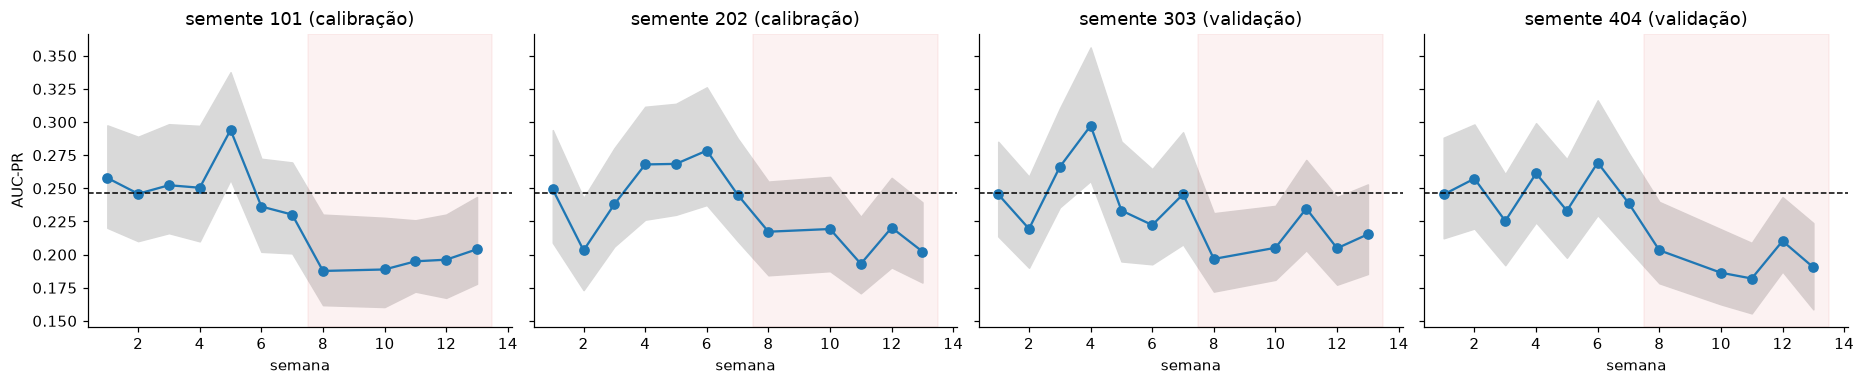

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, (seed, role) in zip(axes, SEEDS.items()):
    rows = [(w["week"], w["performance"]) for w in signals[seed]["weeks"] if "performance" in w]
    weeks = [w for w, _ in rows]
    ax.fill_between(weeks, [p["auc_pr_ci_low"] for _, p in rows], [p["auc_pr_ci_high"] for _, p in rows], color="0.85")
    ax.plot(weeks, [p["auc_pr"] for _, p in rows], "o-", color="tab:blue")
    ax.axhline(baseline["auc_pr"], color="k", ls="--", lw=1)
    ax.axvspan(7.5, 13.5, color="tab:red", alpha=0.06)
    ax.set_title(f"semente {seed} ({role})")
    ax.set_xlabel("semana")
axes[0].set_ylabel("AUC-PR")
plt.tight_layout(); plt.show()

A região vermelha é onde há drift de conceito (a semana 9 não tem rótulos). Na semente 202, a semana 2 (controle) cai
abaixo da linha tracejada por puro acaso, e várias semanas de drift ficam com o intervalo cobrindo a linha de base. Por isso
a regra provisória (queda ≥ 0,04 em **uma** semana) é substituída por uma média móvel de 3 semanas mais 1,645 erros-padrão
ainda abaixo da base: a queda precisa ser maior que o ruído.

## 2. Entrada: o PSI separa controle de drift com folga

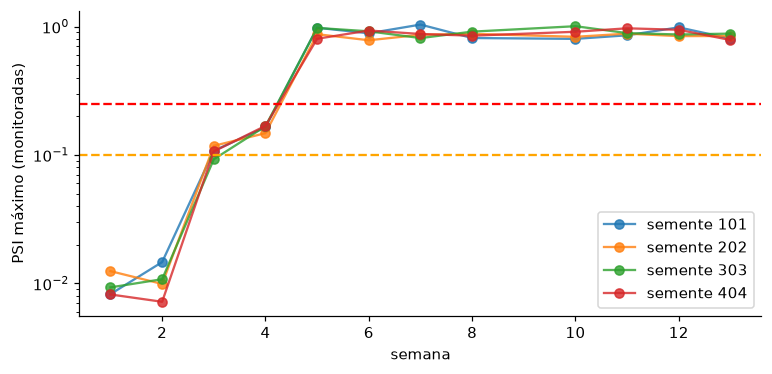

maior PSI visto nas semanas de controle (4 sementes): 0.015, cerca de sete vezes abaixo do limiar de 0,10


In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
for seed in SEEDS:
    rows = [(w["week"], max(r["psi"] for r in w["drift"] if r["feature"] != "SCORE")) for w in signals[seed]["weeks"] if "drift" in w]
    ax.plot(*zip(*rows), "o-", label=f"semente {seed}", alpha=0.8)
ax.axhline(0.10, color="orange", ls="--"); ax.axhline(0.25, color="red", ls="--")
ax.set_yscale("log"); ax.set_xlabel("semana"); ax.set_ylabel("PSI máximo (monitoradas)"); ax.legend(); plt.show()
control = max(max(r["psi"] for r in w["drift"] if r["feature"] != "SCORE") for s in signals.values() for w in s["weeks"] if w["week"] in (1, 2))
print(f"maior PSI visto nas semanas de controle (4 sementes): {control:.3f}, cerca de sete vezes abaixo do limiar de 0,10")

Nas semanas de controle o PSI máximo fica em 0,01–0,015. Exigir **duas** variáveis acima de 0,10 só atrasava o primeiro
alerta (semanas 3–4 mexem uma variável por vez); com **uma**, o alerta vem na semana 3 ou 4 e não há falso alarme.

## 3. Placar: limiares provisórios contra os congelados

In [4]:
rows = []
for seed, role in SEEDS.items():
    for name, t in (("provisório", provisional), ("congelado", frozen)):
        card = replay.scorecard(replay.replay(signals[seed], t))
        rows.append({"semente": seed, "papel": role, "limiares": name,
                     "falso alarme (controle)": card["control_false_alarms"] or "-",
                     "1º alerta de dados": card["first_data_alert_week"],
                     "desempenho: acertos": card["performance_recall"],
                     "desempenho: falsos": card["performance_false_alarms"] or "-",
                     "fatia: acertos": card["slice_recall"], "fatia: falsos": card["slice_false_alarms"] or "-",
                     "diagnóstico correto": card["diagnosis_correct"]})
pd.DataFrame(rows).set_index(["semente", "papel", "limiares"])

falso alarme (controle)  1º alerta de dados  \
semente papel      limiares                                                 
101     calibração provisório                       -                   5   
                   congelado                        -                   3   
202     calibração provisório                     [2]                   5   
                   congelado                        -                   3   
303     validação  provisório                       -                   5   
                   congelado                        -                   4   
404     validação  provisório                       -                   5   
                   congelado                        -                   3   

                              desempenho: acertos desempenho: falsos  \
semente papel      limiares                                            
101     calibração provisório                 5/5                  -   
                   congelado                  5/5                  -   
202     calibração provisório                 2/5                [2]   
                   congelado                  4/5                  -   
303     validação  provisório                 3/5                  -   
                   congelado                  5/5                  -   
404     validação  provisório                 4/5                  -   
                   congelado                  4/5                  -   

                              fatia: acertos fatia: falsos diagnóstico correto  
semente papel      limiares                                                     
101     calibração provisório            2/5             -               13/13  
                   congelado             2/5             -               13/13  
202     calibração provisório            2/5             -                9/13  
                   congelado             2/5             -               12/13  
303     validação  provisório            0/5           [5]               11/13  
                   congelado             0/5           [5]               13/13  
404     validação  provisório            2/5             -               12/13  
                   congelado             2/5             -               12/13

**Como ler.** "Acertos" conta as 5 semanas com drift de conceito (8, 10–13) em que a regra disparou; "falsos" são semanas
sem esse drift em que ela disparou. O diagnóstico é comparado com a verdade do cronograma semana a semana.

## 4. Onde a regra ainda falha

In [5]:
for seed in SEEDS:
    card = replay.scorecard(replay.replay(signals[seed], frozen))
    print(seed, SEEDS[seed], "| diagnósticos errados (obtido, verdade):", card["diagnosis_wrong"] or "nenhum")

101 calibração | diagnósticos errados (obtido, verdade): nenhum
202 calibração | diagnósticos errados (obtido, verdade): {8: ('none', 'concept_drift')}
303 validação | diagnósticos errados (obtido, verdade): nenhum
404 validação | diagnósticos errados (obtido, verdade): {8: ('none', 'concept_drift')}


- **Semana 8** pode passar em branco: a janela de 3 semanas ainda contém semanas saudáveis, então o drift de conceito só
  cruza a regra uma ou duas semanas depois. É o preço de não alarmar por ruído.
- **O alerta de fatia é fraco.** Com o intervalo de confiança exigido, ele quase não dispara em semanas saudáveis (um falso
  em quatro simulações, semana 5 da semente 303), mas acerta poucas semanas com drift; sem a exigência, aciona falsos alarmes em várias semanas sem drift de conceito (14 fatias e ~47
  inadimplentes por fatia fazem alguma fatia parecer ruim por acaso). Mantivemos a regra conservadora e deixamos a **matriz
  de fatias do Grafana** ranquear a queda por fatia, sem depender do alerta.

## 5. Conclusão

| Limiar | Provisório | Congelado | Evidência |
|---|---|---|---|
| variáveis com PSI ≥ 0,10 para alertar | 2 | **1** | controle ≤ 0,01; alerta chega na semana 3–4 |
| queda de desempenho | AUC-PR de 1 semana ≥ 0,04 abaixo | **média de 3 semanas + 1,645 EP < base** | 1 semana tem ±0,04 de ruído; sem falsos na calibração e na validação |
| demais (PSI 0,10/0,25, score, fatia, diagnóstico) | — | inalterados | sem ganho comprovado em mudar |

Limite assumido: as quatro simulações vêm do mesmo simulador (mesmos tipos de drift, mesma fatia). Os limiares foram
validados em sementes novas, não em drifts de natureza desconhecida.